# Munich rents: prediction outside the training range

A model can predict beyond the predictor range observed during fitting. Its
base learners determine how those predictions continue: a P-spline
continues at the slope it had at its boundary knot, a straight line continues
at its slope, and a tree returns the value of its outermost region.

This study fits the same predictor with three learners on apartments up to
100 m², asks each for the rent of apartments between 101 and 160 m², and
compares the answers against the rents those apartments actually carry.

This case teaches how `bbs`, `bols` and `btree` extrapolate beyond the observed
predictor range. It ends with explicit out-of-range predictions and the warnings a user
must decide how to handle.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | what a fitted model returns for inputs outside the range it was fitted on |
| **Observed response** | `rent`, net monthly rent |
| **Estimand** | the fitted effect outside the training range, which no observation constrains |
| **Units** | euros per month; floor area in m² |
| **Sampling unit** | one apartment |
| **Dependence** | clustered by district, as in the rent study |
| **Split / resampling unit** | the apartment |
| **Tuning** | `mstop` by cross-validated risk |
| **Uncertainty** | no intervals are computed; held-out rents assess the extrapolated predictions |
| **Claim type** | methodological |
:::


## The data

`munich_rent` holds the 1999 Munich survey: 3082 apartments with net rent as
the response, and floor area, construction year, three fittings indicators and
a location grade as predictors. [](munich_rents.ipynb) uses the same survey for
the district effects.

The training set is every apartment of 100 m² or less. The 256 apartments
between 101 and 160 m² are held out, so the model is asked about a range it
has no observations in, and the held-out rents provide the comparison.

The survey covers rent-controlled tenancies in one city in one year. It does
not describe owner-occupied housing, new lettings at market rates, or Munich
after 1999.

In [1]:
import warnings

import numpy as np
import polars as pl

import mboostrs as mb

survey = mb.datasets.munich_rent(output="records")
columns = {k: np.asarray(v).astype(float) for k, v in survey.items() if k != "district"}
in_range = columns["area"] <= 100
train = {k: v[in_range] for k, v in columns.items()}
beyond = {k: v[~in_range] for k, v in columns.items()}

print(f"training apartments {len(train['rent']):5d}, area "
      f"{train['area'].min():.0f} to {train['area'].max():.0f} m2")
print(f"held-out apartments {len(beyond['rent']):5d}, area "
      f"{beyond['area'].min():.0f} to {beyond['area'].max():.0f} m2")
for lower in (100, 120, 140):
    band = (columns["area"] >= lower) & (columns["area"] < lower + 20)
    print(f"  observed mean rent {lower:3d}-{lower + 20:3d} m2: "
          f"{columns['rent'][band].mean():6.1f} EUR (n = {int(band.sum())})")

training apartments  2826, area 20 to 100 m2
held-out apartments   256, area 101 to 160 m2
  observed mean rent 100-120 m2:  652.7 EUR (n = 205)
  observed mean rent 120-140 m2:  727.7 EUR (n = 61)
  observed mean rent 140-160 m2:  872.4 EUR (n = 23)


## Floor area as `bbs`, `bols` and `btree`

`bbs(area, df=4)` places a B-spline basis between boundary knots at the minimum
and maximum of the training data, 20 and 100 m². Beyond a boundary knot the
basis is continued linearly, and `predict` raises a warning saying so.

`bols(area)` is a straight line, defined and unchanged over the whole real
line.

`btree(area)` is a sum of stumps. Every apartment above the largest split point
falls in the same terminal region, so all of them receive its value.

The remaining terms are the same in the three models, and each model is stopped
at its own cross-validated iteration count.

In [2]:
others = ("bbs(yearc, df=4) + bols(location) + bols(bath) + bols(kitchen) + "
          "bols(cheating)")

specifications = {
    "bbs": f"rent ~ bbs(area, df=4) + {others}",
    "bols": f"rent ~ bols(area) + {others}",
    "btree": f"rent ~ btree(area) + {others}",
}

query_area = np.array([60.0, 100.0, 130.0, 160.0])

query = {
    "area": query_area,
    "yearc": np.full(4, float(np.median(train["yearc"]))),
    "location": np.ones(4),
    "bath": np.zeros(4),
    "kitchen": np.zeros(4),
    "cheating": np.ones(4),
}

folds = mb.cv_weights(len(train["rent"]), type="kfold", B=5, seed=1)

fits, rows, warned = {}, [], {}


In [3]:
for label, formula in specifications.items():
    model = mb.gamboost(formula, data=train, family=mb.Gaussian(),
                        control=mb.boost_control(1500, 0.1))
    stopped = model[:model.cvrisk(folds=folds).optimal_mstop]
    fits[label] = stopped
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        held_out = np.asarray(stopped.predict(newdata=beyond)).ravel()
        at_query = np.asarray(stopped.predict(newdata=query)).ravel()
        warned[label] = sorted({str(w.message) for w in caught})
    inside = np.asarray(stopped.predict(newdata=train)).ravel()
    rows.append({
        "learner": label,
        "mstop": stopped.mstop,
        "in-range MAE": round(float(np.mean(np.abs(train["rent"] - inside))), 1),
        "held-out MAE": round(float(np.mean(np.abs(beyond["rent"] - held_out))), 1),
        "held-out mean error": round(float(np.mean(beyond["rent"] - held_out)), 1),
        "at 100 m2": round(float(at_query[1])),
        "at 130 m2": round(float(at_query[2])),
        "at 160 m2": round(float(at_query[3])),
    })
# Reuse the declared folds so comparisons differ by model, not by split.
display(pl.DataFrame(rows))

for label, messages in warned.items():
    print(f"{label}: {messages}")


learner,mstop,in-range MAE,held-out MAE,held-out mean error,at 100 m2,at 130 m2,at 160 m2
str,i64,f64,f64,f64,i64,i64,i64
"""bbs""",876,94.5,209.5,-78.4,605,836,1067
"""bols""",949,94.8,190.1,-4.8,581,725,869
"""btree""",619,94.1,196.1,49.9,609,609,609


bbs: ["1 learner(s) are asked to predict outside the range they were fitted on. bbs(area), covariate area: 2 above 100 (worst 0.75 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.75 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.", "1 learner(s) are asked to predict outside the range they were fitted on. bbs(area), covariate area: 256 above 100 (worst 0.75 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.75 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics."]
bo

The three fits agree inside the training range and separate outside it. At
100 m², the last area with data, they give 605, 581 and 609 EUR. At 160 m² they
give 1067, 869 and 609. The observed mean rent of the 23 surveyed apartments
between 140 and 160 m² is 872.4 EUR.

Mean absolute error on the held-out apartments is 209.5 for the P-spline, 190.1
for the straight line and 196.1 for the tree, against 94.5, 94.8 and 94.1
inside the training range. The mean error is signed: the P-spline's fitted
values exceed the held-out rents by 78.4 EUR on average and the tree's fall
short by 49.9.

Only the P-spline reports the extrapolation, through the warning that some
values lie beyond the boundary knots.

In [4]:
import altair as alt
# Evaluate the fitted model on the study's declared rows or prediction grid.
grid_area = np.linspace(20, 160, 141)

grid = {
    "area": grid_area,
    "yearc": np.full(141, float(np.median(train["yearc"]))),
    "location": np.ones(141),
    "bath": np.zeros(141),
    "kitchen": np.zeros(141),
    "cheating": np.ones(141),
}

with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    curve_frame = pl.concat([
        pl.DataFrame({
            "area": grid_area,
            "rent": np.asarray(model.predict(newdata=grid)).ravel(),
            "learner": [label] * 141,
        })
        for label, model in fits.items()
    ])

observed = pl.DataFrame({
    "area": [110.0, 130.0, 150.0],
    "rent": [
        float(columns["rent"][(columns["area"] >= lower) & (columns["area"] < lower + 20)].mean())
        for lower in (100, 120, 140)
    ],
})


/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:2095: ExtrapolationWarning: 1 learner(s) are asked to predict outside the range they were fitted on. bbs(area), covariate area: 60 above 100 (worst 0.75 training ranges out). A spline basis continues by its edge slope outside its boundary knots, which the fit does not constrain -- at 0.75 training ranges out that is an assumption, not an estimate. Pass extrapolation='allow' to accept it, 'clip' to hold the effect flat outside the range instead, or 'error' to refuse. Guide: python -m mboostrs guide modeling-tactics.
  x_data, by_data = self._apply_extrapolation_policy(


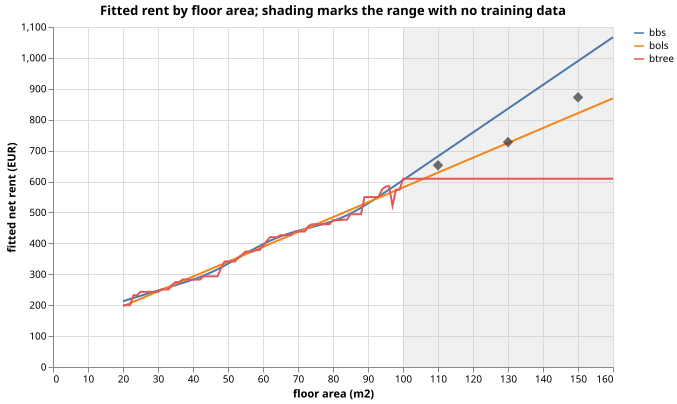

In [5]:
shaded = alt.Chart(pl.DataFrame({"start": [100.0], "end": [160.0]})).mark_rect(
    color="#cccccc", opacity=0.3
).encode(x="start:Q", x2="end:Q")

lines = alt.Chart(curve_frame).mark_line(strokeWidth=2).encode(
    x=alt.X("area:Q", title="floor area (m2)"),
    y=alt.Y("rent:Q", title="fitted net rent (EUR)"),
    color=alt.Color("learner:N", title=None),
)

points = alt.Chart(observed).mark_point(
    size=110, filled=True, color="#333333", shape="diamond"
).encode(x="area:Q", y="rent:Q")

alt.layer(shaded, lines, points).properties(
    title="Fitted rent by floor area; shading marks the range with no training data",
    width=560, height=340,
)


## Boundary knots: `boundary.knots=`

Boundary knots are an argument of the learner, so the basis can be built over
the range the model will be asked about rather than the range it was fitted on.
`bbs(area, df=4, boundary.knots=c(20, 160))` does that, and the training data
are unchanged.

In [6]:
wide = mb.gamboost(
    f"rent ~ bbs(area, df=4, boundary.knots=c(20, 160)) + {others}",
    data=train, family=mb.Gaussian(), control=mb.boost_control(1500, 0.1),
)
wide = wide[:wide.cvrisk(folds=folds).optimal_mstop]

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    held_out = np.asarray(wide.predict(newdata=beyond)).ravel()
    at_query = np.asarray(wide.predict(newdata=query)).ravel()
    messages = sorted({str(w.message) for w in caught})

print(f"mstop {wide.mstop}, held-out MAE "
      f"{np.mean(np.abs(beyond['rent'] - held_out)):.1f}, "
      f"mean error {np.mean(beyond['rent'] - held_out):+.1f}")
print(f"at 130 m2 {at_query[2]:.0f} EUR, at 160 m2 {at_query[3]:.0f} EUR")
print(f"warnings raised: {messages}")

mstop 874, held-out MAE 210.7, mean error -81.7
at 130 m2 841 EUR, at 160 m2 1078 EUR
warnings raised: []


With boundary knots at 20 and 160 the prediction at 160 m² is 1078 EUR against
1067 with the default knots, and the held-out mean absolute error is 210.7
against 209.5. The warning is no longer raised.

The B-splines covering 100 to 160 m² have no observations under them, so their
coefficients are set by the difference penalty rather than by data. With
second-order differences that penalty is smallest when consecutive coefficients
continue the trend at the edge of the data, which is the same straight
continuation the default knots produce.

## Conclusions

The value predicted outside the training range is a property of the learner.
For the same apartment at 160 m² the three fits return 1067, 869 and 609 EUR,
and the mean rent of the 23 surveyed apartments between 140 and 160 m² is
872.4.

Accuracy inside the range does not carry outside it. In-range mean absolute
error is 94.1 to 94.8 EUR for all three fits, and held-out mean absolute error
is 190.1 to 209.5.

Widening the boundary knots changes the basis over the unobserved range while
leaving the training observations unchanged. The prediction at 160 m²
moves from 1067 to 1078 EUR and the held-out error from 209.5 to 210.7, while
the warning that marked the extrapolation is no longer raised.

The lower held-out error of `bols` does not make it the better learner for this
predictor. It follows from the rent-area relation continuing approximately
straight above 100 m², which the training data do not show and the held-out
data are needed to check.

**Applicability.** The comparison uses the 1999 Munich survey, floor areas up
to 160 m², and a fit
in which the other terms stay inside their own observed ranges. A prediction
outside the range of several predictors at once compounds the same problem
across learners.